# Einstieg in Probly

Wir schätzen zuerst einen Kaufpreis mit einer Geraden. Danach quantifizieren und erklären wir die Unsicherheit von MC Dropout bei Two Moons.

In [158]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import shapiq
from sklearn.datasets import make_moons
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import torch
from torch import nn

from probly.evaluation.selective_prediction import selective_prediction
from probly.method import dropout, ensemble
from probly.quantification import quantify
from probly.representer import representer

SEED = 0
torch.manual_seed(SEED)
torch.set_num_threads(1)  # Die kleinen Netze laufen auf der CPU.

## Eigenes Testen mit eigenen Beispiel-Daten: Einfluss von Kilometerstand auf den Verkaufspreis

Idee: 24 Gebrauchtwagen simulieren.
Der Kaufpreis sinkt pro 1.000 km um 120 €. 
Zufällige Streuung von 1.500 € Standardabweichung (Platzhalter für Unterschiede im Zustand der Autos)

Schätzung via lineare Regression aus den Beobachtungen. 
Mit Probly daraus ein Ensemble.

In [159]:
car_data_rng = np.random.default_rng(SEED)
car_km = np.linspace(30_000, 150_000, 24)
car_price = - 0.12 * car_km + car_data_rng.normal(0, 1_500, size=car_km.size) + 30_000
car_features = car_km[:, None]  # Eine Zeile pro Auto, eine Spalte für den Kilometerstand.

### Von einer Geraden zum Bootstrap-Ensemble

`ensemble` erzeugt 50 Kopien von `LinearRegression`

Jede Kopie eine eigene Bootstrap-Stichprobe -> 24 Autos mit Zurücklegen aus den 24 Beobachtungen ziehen

`representer` sammelt Preisvorhersagen pro Kilometerstand

`quantify` berechnet die Varianz dieser Vorhersagen.

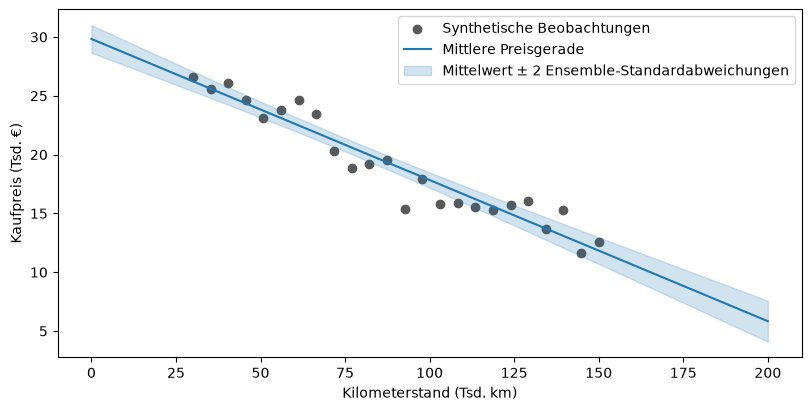

In [160]:
car_ensemble = ensemble(LinearRegression(), num_members=50)
car_bootstrap_rng = np.random.default_rng(SEED + 1)
for member in car_ensemble:
    rows = car_bootstrap_rng.integers(0, car_km.size, size=car_km.size)
    member.fit(car_features[rows], car_price[rows])

car_km_grid = np.linspace(0, 200_000, 201)
car_rep = representer(car_ensemble)
car_predictions = car_rep.represent(car_km_grid[:, None])
car_mean = car_predictions.sample_mean()
car_variance = quantify(car_predictions).total
car_std = np.sqrt(car_variance)  # Von Euro² zurück zu Euro.

fig, car_ax = plt.subplots(figsize=(8, 4), layout="constrained")
car_ax.scatter(car_km / 1_000, car_price / 1_000, color="0.35", label="Synthetische Beobachtungen")
car_ax.plot(car_km_grid / 1_000, car_mean / 1_000, color="tab:blue", label="Mittlere Preisgerade")
car_ax.fill_between(
    car_km_grid / 1_000,
    (car_mean - 2 * car_std) / 1_000,
    (car_mean + 2 * car_std) / 1_000,
    color="tab:blue",
    alpha=0.2,
    label="Mittelwert ± 2 Ensemble-Standardabweichungen",
)
car_ax.set(xlabel="Kilometerstand (Tsd. km)", ylabel="Kaufpreis (Tsd. €)")
car_ax.legend()
plt.show()

### Was erklärt der Kilometerstand mit shapiq?

Wir erklären zwei Ausgaben desselben Probly-Ensembles. Die **Preisprognose** ist der Mittelwert der 50 Geraden. Die **Modellstreuung** ist ihre Standardabweichung in Euro, also die Größe, aus der wir das Band im Plot berechnet haben.

Für jede Ausgabe bildet shapiq einen eigenen Referenzwert als Durchschnitt über die 24 beobachteten Kilometerstände. Der Kilometerstand ist unser einziges Merkmal. Sein Shapley-Wert ist daher genau die Abweichung der jeweiligen Ausgabe von ihrem Referenzwert. [shapiq Quickstart](https://shapiq.readthedocs.io/en/latest/introduction/start.html#shapley-values-as-in-shap)

In [161]:
def car_mean_price(rows):
    return car_rep.represent(rows).sample_mean()


def car_model_spread(rows):
    return np.sqrt(quantify(car_rep.represent(rows)).total)


car_explanation_rows = [
    "| Ausgabe | Kilometerstand | Referenzwert | Beitrag des Kilometerstands | Probly-Wert |",
    "| :--- | ---: | ---: | ---: | ---: |",
]
for label, score in (
    ("Mittlerer Preis", car_mean_price),
    ("Modellstreuung", car_model_spread),
):
    car_explainer = shapiq.TabularExplainer(
        score,
        data=car_features,
        imputer="marginal",
        sample_size=None,
        index="SV",
        max_order=1,
        random_state=SEED,
    )
    for km in (30_000, 40_268, 77_000, 90_000, 100_000, 113_227, 200_000):
        car_point = np.array([float(km)])
        car_explanation = car_explainer.explain(car_point, budget=2)
        baseline = car_explanation.baseline_value
        contribution = car_explanation[(0,)]
        value = score(car_point[None, :])[0]

        np.testing.assert_allclose(baseline + contribution, value, atol=1e-8)
        km_label = f"{km:,}".replace(",", ".")
        car_explanation_rows.append(
            f"| {label} | {km_label} km | {baseline:.2f} € | {contribution:+.2f} € | {value:.2f} € |"
        )

display(Markdown("\n".join(car_explanation_rows)))

| Ausgabe | Kilometerstand | Referenzwert | Beitrag des Kilometerstands | Probly-Wert |
| :--- | ---: | ---: | ---: | ---: |
| Mittlerer Preis | 30.000 km | 19030.92 € | +7198.13 € | 26229.05 € |
| Mittlerer Preis | 40.268 km | 19030.92 € | +5966.29 € | 24997.21 € |
| Mittlerer Preis | 77.000 km | 19030.92 € | +1559.59 € | 20590.51 € |
| Mittlerer Preis | 90.000 km | 19030.92 € | +0.00 € | 19030.92 € |
| Mittlerer Preis | 100.000 km | 19030.92 € | -1199.69 € | 17831.23 € |
| Mittlerer Preis | 113.227 km | 19030.92 € | -2786.52 € | 16244.40 € |
| Mittlerer Preis | 200.000 km | 19030.92 € | -13196.57 € | 5834.34 € |
| Modellstreuung | 30.000 km | 375.47 € | +47.60 € | 423.07 € |
| Modellstreuung | 40.268 km | 375.47 € | -0.00 € | 375.47 € |
| Modellstreuung | 77.000 km | 375.47 € | -89.49 € | 285.98 € |
| Modellstreuung | 90.000 km | 375.47 € | -76.14 € | 299.32 € |
| Modellstreuung | 100.000 km | 375.47 € | -50.15 € | 325.32 € |
| Modellstreuung | 113.227 km | 375.47 € | -0.00 € | 375.47 € |
| Modellstreuung | 200.000 km | 375.47 € | +494.88 € | 870.35 € |

- **Probly-Wert** = Referenzwert + shapiq-Beitrag. Er zeigt je nach Zeile den mittleren Preis oder die Standardabweichung der 50 Preisvorhersagen.
- **Mittlerer Preis:** Bei 90.000 km entspricht die Prognose dem Referenzwert von 19.030,92 €. Bei 100.000 km liegt sie 1.199,69 € darunter. Der Abschlag bezieht sich auf den Durchschnitt der Preisprognosen.
- **Modellstreuung:** Bei 40.268 und 113.227 km entspricht sie gerundet dem Referenzwert von 375,47 €. Bei 100.000 km liegt sie 50,15 € darunter und beträgt damit 325,32 €.
- **200.000 km** liegen außerhalb der Trainingsdaten. Der geschätzte Preis sinkt auf 5.834,34 €, während die Modelle mit 870,35 € deutlich stärker streuen.

---


## Two Moons

In [162]:
class MLPClassifier(nn.Module):
    def __init__(
        self, in_features: int = 2, hidden_features: int = 64, out_features: int = 2
    ) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, hidden_features),
            nn.ReLU(),
            nn.Linear(hidden_features, out_features),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

In [163]:
X, y = make_moons(n_samples=500, noise=0.05, random_state=0)
X_tensor = torch.from_numpy(X).float()
y_tensor = torch.from_numpy(y).long()

## 0. Überblick

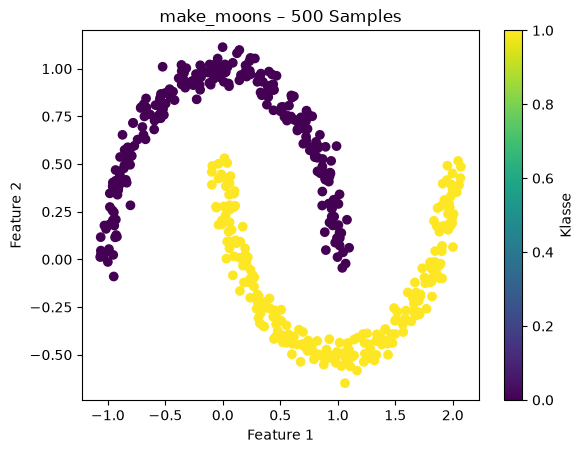

In [164]:
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("make_moons – 500 Samples")
plt.colorbar(label="Klasse")
plt.show()

## 1. Transformation

In [165]:
base_model = MLPClassifier()

dropout_model = dropout(
    base_model,
    p=0.5,
    predictor_type="logit_classifier",
    shared_mask=True,
)

In [166]:
opt = torch.optim.Adam(dropout_model.parameters(), lr=1e-3)

dropout_model.train()
for _ in range(300):
    opt.zero_grad()
    loss = nn.functional.cross_entropy(dropout_model(X_tensor), y_tensor)
    loss.backward()
    opt.step()

dropout_model.eval();

## 2. Repräsentation

Der Representer sammelt für jeden Punkt 100 stochastische Vorhersagen. Die gemeinsame Funktion nutzt bei jedem Aufruf dieselbe Folge von Dropout-Masken und stellt danach den Zufallszustand wieder her.

In [167]:
rep = representer(dropout_model, num_samples=100)


def mc_representation(rows):
    inputs = torch.as_tensor(rows, dtype=torch.float32)
    with torch.random.fork_rng(devices=[]), torch.no_grad():
        torch.random.default_generator.manual_seed(SEED)
        return rep.represent(inputs)


representation = mc_representation(X_tensor)

## 3. Quantifizierung

`quantify` berechnet aus den Vorhersagen unter anderem die Gesamtunsicherheit pro Punkt.

In [168]:
quantification = quantify(representation)
uncertainty = quantification.total.cpu().numpy()

## 4. Evaluation

Wir wählen die Klasse mit der höchsten mittleren Wahrscheinlichkeit aus den 100 Vorhersagen. Bei der selektiven Vorhersage werden die unsichersten Punkte zuerst ausgeblendet. Die AURC fasst zusammen, wie sich die Fehlerrate der verbleibenden Punkte verändert. Hier berechnen wir sie auf den Trainingsdaten.

Die Kurve zeigt die Fehlerrate für den jeweils verbleibenden Anteil der Trainingspunkte. Bei 100 % bleiben alle Punkte, bei kleinerer Abdeckung nur die mit geringerer Unsicherheit.

In [169]:
predictions = representation.sample_mean().probabilities.argmax(dim=-1)
losses = (predictions != y_tensor).float().numpy()

aurc, bin_losses = selective_prediction(uncertainty, losses)
print(f"AURC auf den Trainingsdaten = {aurc:.4f}")

AURC auf den Trainingsdaten = 0.0071


In [170]:
anzahl_falsch_klassifiziert = np.count_nonzero(losses == 1)
anzahl_richtig_klassifiziert = np.count_nonzero(losses == 0)

print(f"Falsch klassifiziert (1er): {anzahl_falsch_klassifiziert},\nRichtig klassifiziert (0er): {anzahl_richtig_klassifiziert}\n")
print(anzahl_falsch_klassifiziert / anzahl_richtig_klassifiziert)

Falsch klassifiziert (1er): 37,
Richtig klassifiziert (0er): 463

0.07991360691144708


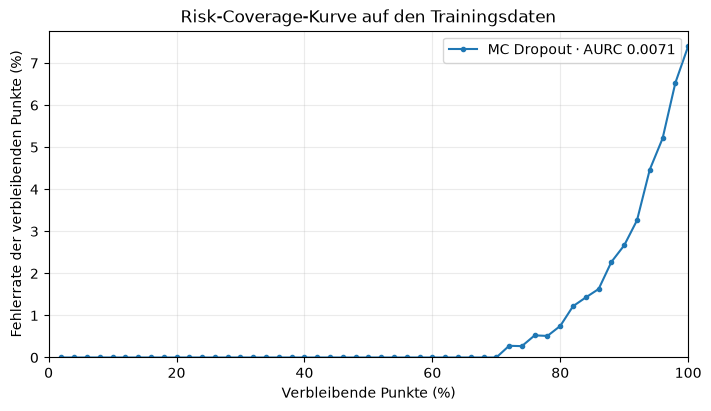

In [171]:
# Probly entfernt pro Schritt einen gleich großen Block der unsichersten Punkte.
bin_size = losses.size // bin_losses.size
remaining = losses.size - np.arange(bin_losses.size) * bin_size
coverage = remaining / losses.size

fig, risk_ax = plt.subplots(figsize=(7, 4), layout="constrained")
risk_ax.plot(100 * coverage, 100 * bin_losses, marker=".", label=f"MC Dropout · AURC {aurc:.4f}")
risk_ax.set(
    title="Risk-Coverage-Kurve auf den Trainingsdaten",
    xlabel="Verbleibende Punkte (%)",
    ylabel="Fehlerrate der verbleibenden Punkte (%)",
    xlim=(0, 100),
    ylim=(0, None),
)
risk_ax.grid(alpha=0.25)
risk_ax.legend()
plt.show()

## 5. Epistemische Unsicherheit mit shapiq erklären

Für shapiq die selbe MC-Dropout-Repräsentation zum betrachten der epistemischen Unsicherheit. 

Wir untersuchen, wie die beiden Koordinaten und ihre Wechselwirkung zu diesem Wert beitragen.

Der Referenzwert ist die mittlere epistemische Unsicherheit auf den Trainingsdaten. Die gestrichelte Kontur zeigt, wo die Unsicherheit genau diesem Wert entspricht. 

Fehlt eine Koordinate, ergänzt der marginale Imputer sie aus den Trainingsdaten. Dabei können auch Kombinationen entstehen, die abseits der Monde liegen. 

Mit zwei Koordinaten gibt es vier Teilmengen, die shapiq mit `budget=4` alle auswertet. 

In [172]:
def epistemic_score(rows):
    return quantify(mc_representation(rows)).epistemic.cpu().numpy()


uncertainty_explainer = shapiq.TabularExplainer(
    epistemic_score,
    data=X,
    imputer="marginal",
    sample_size=None,
    index="k-SII",
    max_order=2,
    random_state=SEED,
)

In [179]:
scores = epistemic_score(X)
top_indices = np.argsort(-scores, kind="stable")[:6]
ranked_points = {f"A{rank}": X[index] for rank, index in enumerate(top_indices, start=1)}
points = {
    **ranked_points,
    "B": np.array([3.0, 2.0]),
    "C": np.array([1.0, 0.0]),
    "D": np.array([3.0, 1.3]),
}
point_explanations = {}
table = [
    "| Punkt | Koordinaten | Referenzwert | x₁ | x₂ | x₁ × x₂ | Probly |",
    "| :--- | :--- | ---: | ---: | ---: | ---: | ---: |",
]
for label, point in points.items():
    explanation = uncertainty_explainer.explain(point, budget=4)
    baseline = explanation.baseline_value
    contributions = np.array([explanation[key] for key in ((0,), (1,), (0, 1))])
    score = epistemic_score(point[None, :])[0]

    np.testing.assert_allclose(baseline + contributions.sum(), score, atol=1e-6)
    point_explanations[label] = explanation

    x1, x2, interaction = contributions
    table.append(
        f"| {label} | ({point[0]:.3f}, {point[1]:.3f}) | {baseline:.4f} | "
        f"{x1:+.4f} | {x2:+.4f} | {interaction:+.4f} | {score:.4f} |"
    )

display(Markdown("\n".join(table)))

| Punkt | Koordinaten | Referenzwert | x₁ | x₂ | x₁ × x₂ | Probly |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: |
| A1 | (2.047, 0.516) | 0.0481 | +0.0829 | +0.0484 | +0.0486 | 0.2280 |
| A2 | (1.953, 0.491) | 0.0481 | +0.0782 | +0.0496 | +0.0417 | 0.2175 |
| A3 | (2.071, 0.485) | 0.0481 | +0.0840 | +0.0498 | +0.0304 | 0.2123 |
| A4 | (1.998, 0.451) | 0.0481 | +0.0805 | +0.0508 | +0.0183 | 0.1977 |
| A5 | (1.948, 0.416) | 0.0481 | +0.0779 | +0.0511 | +0.0048 | 0.1819 |
| A6 | (2.066, 0.427) | 0.0481 | +0.0838 | +0.0511 | -0.0025 | 0.1805 |
| B | (3.000, 2.000) | 0.0481 | +0.0862 | -0.0204 | +0.1718 | 0.2857 |
| C | (1.000, 0.000) | 0.0481 | +0.0135 | +0.0180 | -0.0136 | 0.0660 |
| D | (3.000, 1.300) | 0.0481 | +0.0862 | -0.0026 | +0.2714 | 0.4031 |

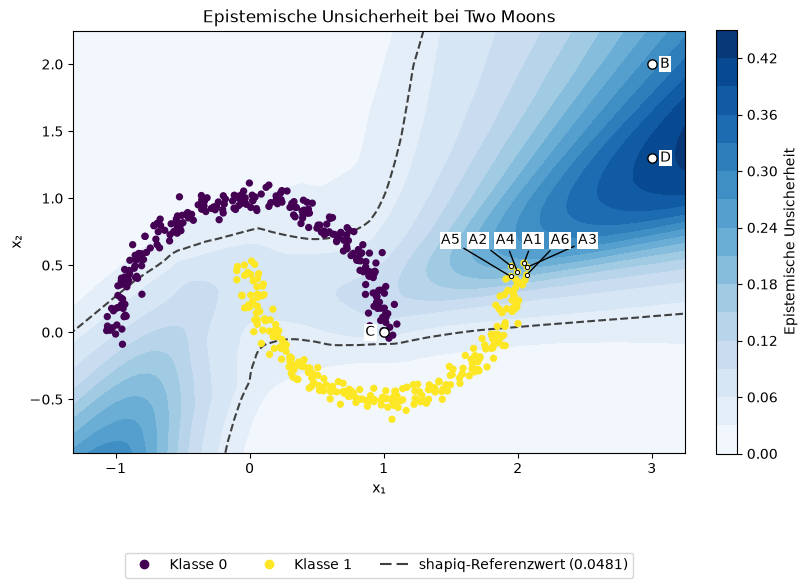

**Punkt A1**

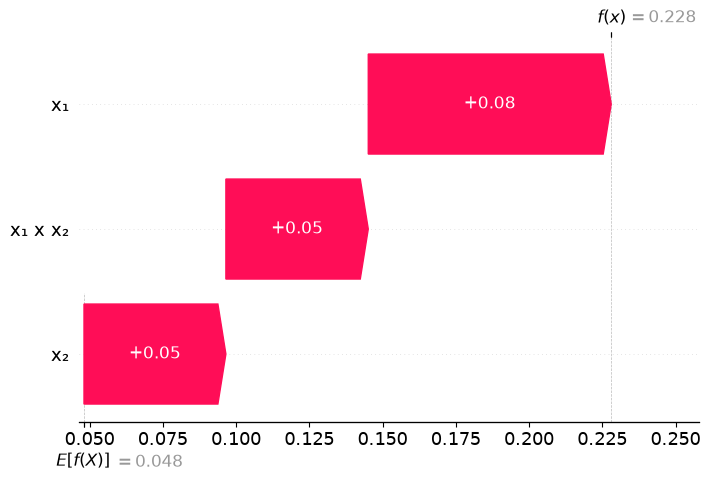

**Punkt A2**

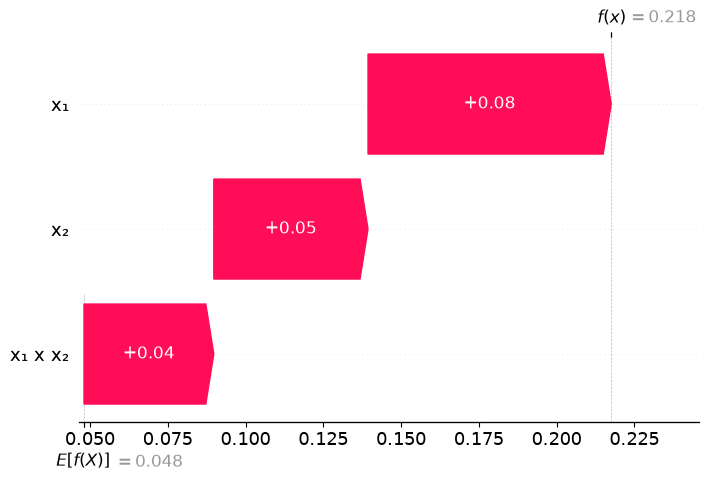

**Punkt A3**

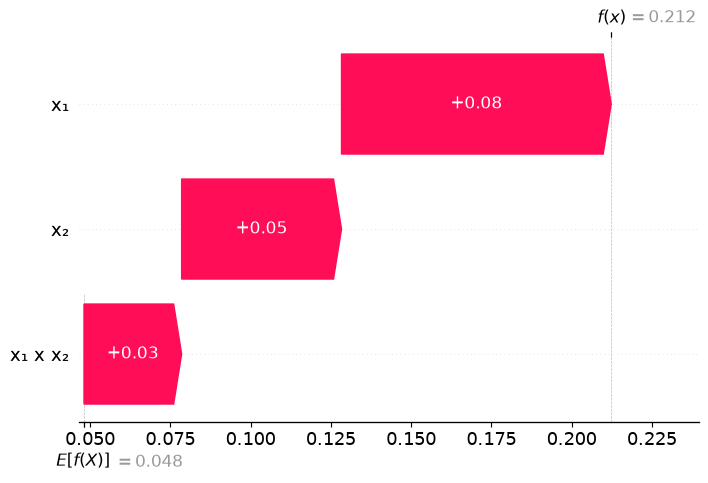

**Punkt A4**

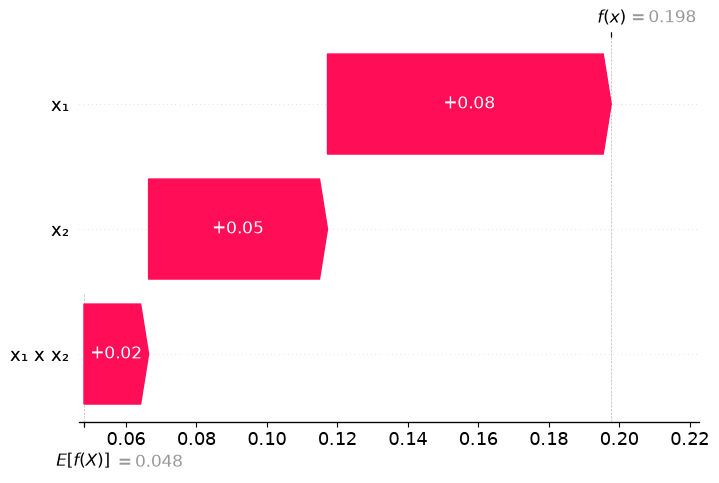

**Punkt A5**

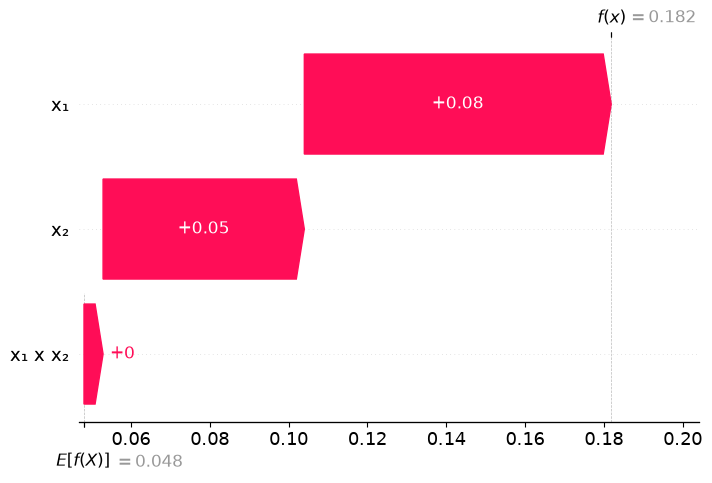

**Punkt A6**

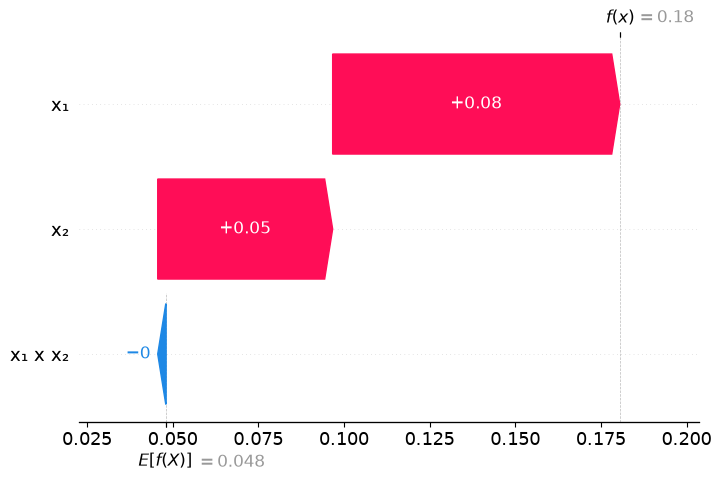

**Punkt B**

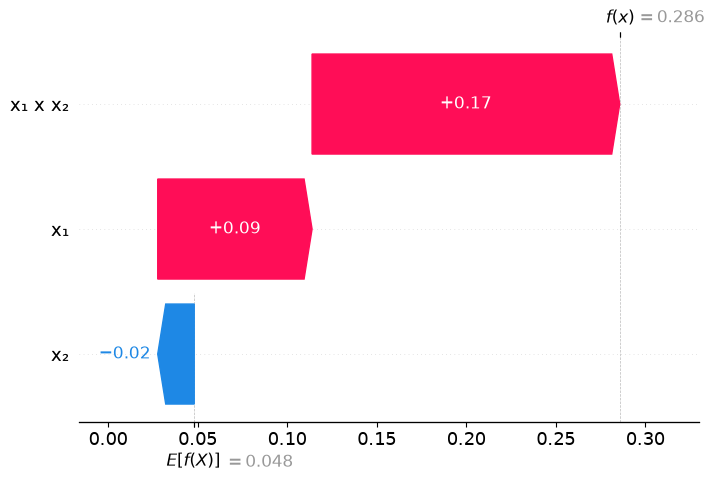

**Punkt C**

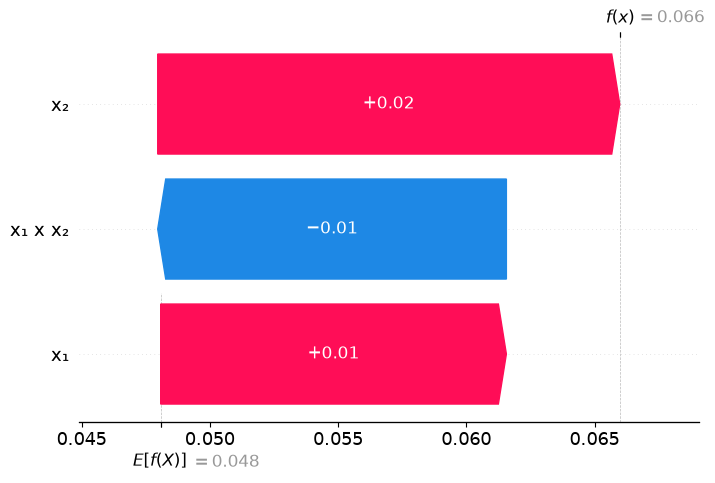

**Punkt D**

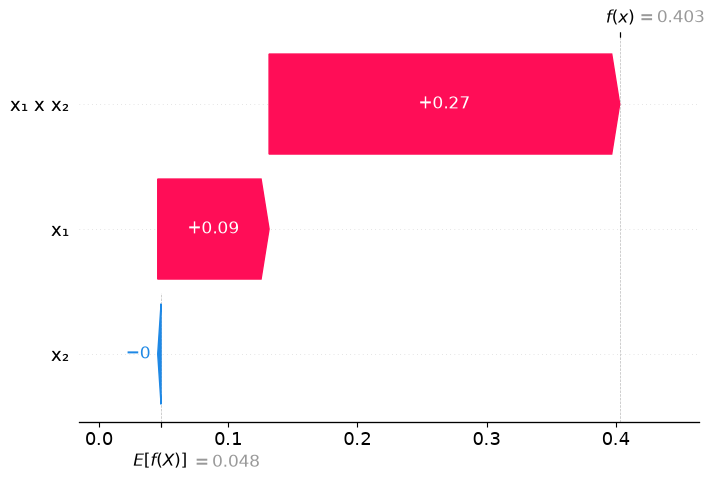

In [180]:
# Die A-Labels stehen von links nach rechts über den dicht beieinanderliegenden Punkten.
ranked_labels = sorted(ranked_points, key=lambda label: ranked_points[label][0])
ranked_xy = X[top_indices]
label_x = np.linspace(ranked_xy[:, 0].min() - 0.45, ranked_xy[:, 0].max() + 0.45, len(ranked_labels))
label_y = ranked_xy[:, 1].max() + 0.17
ranked_label_x = dict(zip(ranked_labels, label_x))

plot_points = np.vstack([X, *points.values(), [label_x[0], label_y], [label_x[-1], label_y]])
lower = plot_points.min(axis=0) - 0.25
upper = plot_points.max(axis=0) + 0.25
grid_x, grid_y = np.meshgrid(
    np.linspace(lower[0], upper[0], 100),
    np.linspace(lower[1], upper[1], 100),
)
grid = np.column_stack((grid_x.ravel(), grid_y.ravel()))
grid_uncertainty = epistemic_score(grid).reshape(grid_x.shape)

fig, moons_ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
uncertainty_map = moons_ax.contourf(grid_x, grid_y, grid_uncertainty, levels=15, cmap="Blues")
fig.colorbar(uncertainty_map, ax=moons_ax, label="Epistemische Unsicherheit")
reference_value = uncertainty_explainer.baseline_value
reference_contour = moons_ax.contour(
    grid_x, grid_y, grid_uncertainty, levels=[reference_value],
    colors="0.25", linestyles="--", zorder=1,
)
classes = moons_ax.scatter(X[:, 0], X[:, 1], c=y, s=18)
label_box = {"facecolor": "white", "edgecolor": "none", "pad": 1}
for i, (label, point) in enumerate(points.items()):
    if label in ranked_label_x:
        moons_ax.scatter(*point, s=9, facecolor="white", edgecolor="black", linewidth=0.7)
        moons_ax.annotate(
            label, point, xytext=(ranked_label_x[label], label_y),
            ha="center", va="center", bbox=label_box, arrowprops={"arrowstyle": "-"},
        )
        continue
    moons_ax.scatter(*point, s=45, facecolor="white", edgecolor="black")
    right = i % 2 == 0
    moons_ax.annotate(
        label, point, xytext=(6 if right else -6, 0),
        textcoords="offset points", ha="left" if right else "right", va="center",
        bbox=label_box,
    )

class_handles, _ = classes.legend_elements()
reference_handles, _ = reference_contour.legend_elements()
moons_ax.legend(
    [*class_handles, *reference_handles],
    ["Klasse 0", "Klasse 1", f"shapiq-Referenzwert ({reference_value:.4f})"],
    loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=3,
)
moons_ax.set(title="Epistemische Unsicherheit bei Two Moons", xlabel="x₁", ylabel="x₂", aspect="equal")
plt.show()

feature_names = np.array(["x₁", "x₂"])
for label, explanation in point_explanations.items():
    display(Markdown(f"**Punkt {label}**"))
    plt.figure()
    explanation.plot_waterfall(feature_names=feature_names, abbreviate=False)